In [1]:
from google.colab import drive
from pathlib import Path
import json

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/vhap")
IMG = ROOT / "data" / "ueyes_web" / "images"
SAL = ROOT / "data" / "ueyes_web" / "saliency_maps"
FIX = ROOT / "data" / "ueyes_web" / "fixations"
split_path = ROOT / "data" / "splits.json"

print("splits.json exists:", split_path.exists())
splits = json.loads(split_path.read_text())
print({k: len(v) for k, v in splits.items()})

Mounted at /content/drive
splits.json exists: True
{'train': 346, 'val': 74, 'test': 75}


In [2]:
def stems(folder):
    return {p.stem for p in Path(folder).iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}}

on_disk = stems(IMG)
train, val, test = set(splits["train"]), set(splits["val"]), set(splits["test"])

assert train.isdisjoint(val)
assert train.isdisjoint(test)
assert val.isdisjoint(test)
assert train | val | test == on_disk
assert all(stem in stems(SAL) and stem in stems(FIX) for stem in on_disk)
print("Split check passed.", len(on_disk), "pages, no page in more than one set.")

Split check passed. 495 pages, no page in more than one set.


In [3]:
from sklearn.model_selection import KFold

pool = splits["train"] + splits["val"]
fold_path = ROOT / "data" / "folds.json"

if fold_path.exists():
    folds = json.loads(fold_path.read_text())["folds"]
    print("Loaded existing folds. Do not rebuild them.")
else:
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    folds = []
    for tr_idx, va_idx in kf.split(pool):
        folds.append({
            "train": [pool[i] for i in tr_idx],
            "val": [pool[i] for i in va_idx],
        })
    fold_path.write_text(json.dumps({"test": splits["test"], "folds": folds}, indent=2))
    print("Wrote", fold_path)

test = set(splits["test"])
pool_set = set(pool)
for i, fold in enumerate(folds):
    tr, va = set(fold["train"]), set(fold["val"])
    assert tr.isdisjoint(va)
    assert tr.isdisjoint(test) and va.isdisjoint(test)
    assert tr | va == pool_set
    print(f"fold {i}: train {len(tr)}  val {len(va)}")
print("Fold check passed. Test pages are in none of the folds.")

Wrote /content/drive/MyDrive/vhap/data/folds.json
fold 0: train 336  val 84
fold 1: train 336  val 84
fold 2: train 336  val 84
fold 3: train 336  val 84
fold 4: train 336  val 84
Fold check passed. Test pages are in none of the folds.


In [4]:
import shutil
local = Path("/content/ueyes_web")
if not local.exists():
    shutil.copytree(ROOT / "data" / "ueyes_web", local)
print("local images", len(list((local / "images").glob("*"))))

local images 495


In [5]:
src = ROOT / "src"
src.mkdir(exist_ok=True)
(src / "dataset.py").write_text(r'''
import cv2
import numpy as np
import torch
from pathlib import Path
from torch.utils.data import Dataset

SHAPE_R, SHAPE_C = 288, 384

def find_by_stem(folder, stem):
    folder = Path(folder)
    for ext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        hit = folder / f"{stem}{ext}"
        if hit.exists():
            return hit
    hits = list(folder.glob(stem + ".*"))
    if not hits:
        raise FileNotFoundError(f"{stem} not in {folder}")
    return hits[0]

def resize_pad(img, interpolation=cv2.INTER_LINEAR, pad_value=0):
    """Same geometry as TranSalNet utils/data_process.py preprocess_img."""
    orig_h, orig_w = img.shape[:2]
    if img.ndim == 2:
        padded = np.full((SHAPE_R, SHAPE_C), pad_value, dtype=img.dtype)
    else:
        padded = np.full((SHAPE_R, SHAPE_C, img.shape[2]), pad_value, dtype=img.dtype)
    rows_rate = orig_h / SHAPE_R
    cols_rate = orig_w / SHAPE_C
    if rows_rate > cols_rate:
        new_cols = (orig_w * SHAPE_R) // orig_h
        resized = cv2.resize(img, (new_cols, SHAPE_R), interpolation=interpolation)
        if new_cols > SHAPE_C:
            resized = cv2.resize(img, (SHAPE_C, SHAPE_R), interpolation=interpolation)
            new_cols = SHAPE_C
        start = (SHAPE_C - new_cols) // 2
        padded[:, start:start + new_cols] = resized
    else:
        new_rows = (orig_h * SHAPE_C) // orig_w
        resized = cv2.resize(img, (SHAPE_C, new_rows), interpolation=interpolation)
        if new_rows > SHAPE_R:
            resized = cv2.resize(img, (SHAPE_C, SHAPE_R), interpolation=interpolation)
            new_rows = SHAPE_R
        start = (SHAPE_R - new_rows) // 2
        padded[start:start + new_rows, :] = resized
    return padded

def light_augment(img):
    """Colour only. img is uint8 BGR. Layout is unchanged."""
    alpha = np.random.uniform(0.9, 1.1)
    beta = np.random.uniform(-15, 15)
    out = np.clip(img.astype(np.float32) * alpha + beta, 0, 255)
    out = np.clip(out + np.random.normal(0, 5, out.shape), 0, 255).astype(np.uint8)
    quality = int(np.random.randint(75, 96))
    ok, encoded = cv2.imencode(".jpg", out, [int(cv2.IMWRITE_JPEG_QUALITY), quality])
    if ok:
        out = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    return out

class UEyesWebDataset(Dataset):
    def __init__(self, root, ids, augment=False):
        self.root = Path(root)
        self.ids = list(ids)
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        stem = self.ids[index]
        image = cv2.imread(str(find_by_stem(self.root / "images", stem)))
        sal = cv2.imread(str(find_by_stem(self.root / "saliency_maps", stem)), cv2.IMREAD_GRAYSCALE)
        fix = cv2.imread(str(find_by_stem(self.root / "fixations", stem)), cv2.IMREAD_GRAYSCALE)

        if self.augment:
            image = light_augment(image)

        image = resize_pad(image, cv2.INTER_LINEAR, pad_value=1)
        sal = resize_pad(sal, cv2.INTER_LINEAR, pad_value=0).astype(np.float32)
        fix = resize_pad(fix, cv2.INTER_NEAREST, pad_value=0)

        image = np.transpose(image.astype(np.float32) / 255.0, (2, 0, 1))
        sal_01 = sal / (sal.max() + 1e-8)
        sal_dist = sal_01 / (sal_01.sum() + 1e-8)
        fix = (fix > 0).astype(np.float32)

        return {
            "id": stem,
            "image": torch.from_numpy(image),
            "saliency_01": torch.from_numpy(sal_01).unsqueeze(0),
            "saliency_dist": torch.from_numpy(sal_dist).unsqueeze(0),
            "fixation": torch.from_numpy(fix).unsqueeze(0),
        }
''')
print("Wrote", src / "dataset.py")

Wrote /content/drive/MyDrive/vhap/src/dataset.py


In [6]:
import sys
sys.path.append(str(ROOT / "src"))
import cv2, numpy as np
from dataset import find_by_stem, resize_pad
from utils.data_process import preprocess_img

stem = splits["train"][0]
path = find_by_stem(Path("/content/ueyes_web/images"), stem)
official = preprocess_img(str(path))
ours = resize_pad(cv2.imread(str(path)), cv2.INTER_LINEAR, pad_value=1)
print(stem, official.shape, ours.shape, "match:", np.array_equal(official, ours))

ModuleNotFoundError: No module named 'utils'

In [7]:
from pathlib import Path
import sys

repo = Path("/content/TranSalNet")
if not (repo / "utils" / "data_process.py").exists():
    %cd /content
    !git clone https://github.com/LJOVO/TranSalNet.git

sys.path.append("/content/TranSalNet")
print("TranSalNet found:", (repo / "utils" / "data_process.py").exists())

/content
Cloning into 'TranSalNet'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 58 (delta 6), reused 3 (delta 3), pack-reused 43 (from 1)
Receiving objects: 100% (58/58), 3.14 MiB | 13.52 MiB/s, done.
Resolving deltas: 100% (9/9), done.
TranSalNet found: True


In [8]:
import sys
from pathlib import Path
sys.path.append(str(ROOT / "src"))
sys.path.append("/content/TranSalNet")

import cv2, numpy as np
from dataset import find_by_stem, resize_pad
from utils.data_process import preprocess_img

stem = splits["train"][0]
path = find_by_stem(Path("/content/ueyes_web/images"), stem)
official = preprocess_img(str(path))
ours = resize_pad(cv2.imread(str(path)), cv2.INTER_LINEAR, pad_value=1)
print(stem, official.shape, ours.shape, "match:", np.array_equal(official, ours))

3eb8f9 (288, 384, 3) (288, 384, 3) match: True


In [9]:
from torch.utils.data import DataLoader
from dataset import UEyesWebDataset

train_ds = UEyesWebDataset("/content/ueyes_web", splits["train"], augment=True)
val_ds = UEyesWebDataset("/content/ueyes_web", splits["val"], augment=False)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)

batch = next(iter(train_loader))
image, sal_01, sal_dist, fix = batch["image"], batch["saliency_01"], batch["saliency_dist"], batch["fixation"]
print("image", tuple(image.shape), float(image.min()), float(image.max()))
print("saliency_01", tuple(sal_01.shape), float(sal_01.min()), float(sal_01.max()))
print("saliency_dist sum per map", sal_dist.flatten(1).sum(1).tolist())
print("fixation", tuple(fix.shape), "positives", int(fix.sum()))
print("val length", len(val_ds), "augment", val_ds.augment)

image (4, 3, 288, 384) 0.0 1.0
saliency_01 (4, 1, 288, 384) 0.0 1.0
saliency_dist sum per map [1.0000001192092896, 1.0, 1.0, 0.9999998211860657]
fixation (4, 1, 288, 384) positives 2337
val length 74 augment False


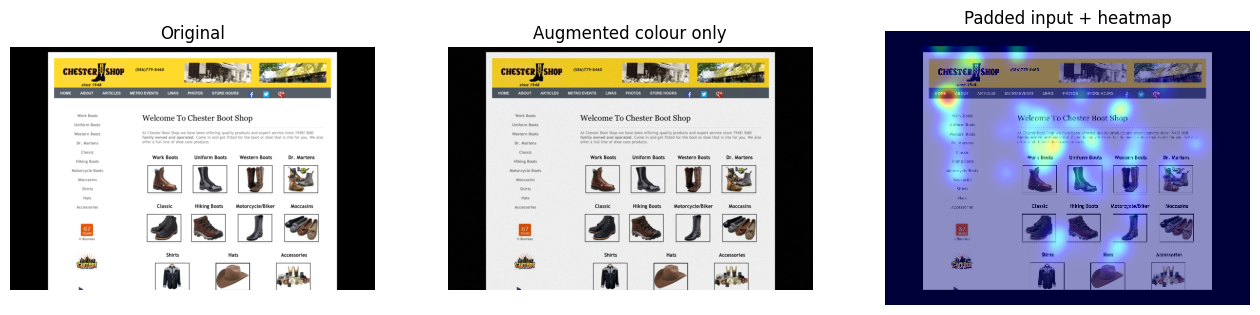

In [10]:
import matplotlib.pyplot as plt
import cv2
from dataset import find_by_stem, light_augment, resize_pad

stem = splits["train"][0]
path = find_by_stem(Path("/content/ueyes_web/images"), stem)
sal_path = find_by_stem(Path("/content/ueyes_web/saliency_maps"), stem)
original = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
changed = cv2.cvtColor(light_augment(cv2.imread(str(path))), cv2.COLOR_BGR2RGB)
sal = resize_pad(cv2.imread(str(sal_path), cv2.IMREAD_GRAYSCALE), pad_value=0)
view = resize_pad(cv2.cvtColor(original, cv2.COLOR_RGB2BGR), pad_value=1)
view = cv2.cvtColor(view, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(original); axes[0].set_title("Original")
axes[1].imshow(changed); axes[1].set_title("Augmented colour only")
axes[2].imshow(view); axes[2].imshow(sal, cmap="jet", alpha=0.45); axes[2].set_title("Padded input + heatmap")
for ax in axes:
    ax.axis("off")
plt.show()